In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar `creditsight` sin instalarlo: el código vive en ejemplo/src
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 07 · Validación e interpretación — abrir la prueba, una sola vez

Hasta aquí todo se decidió con **validación**. La **prueba** (el 20 % de los clientes que nadie ha mirado) se abre hoy,
**una sola vez**, para medir cómo se comportará el modelo con clientes nuevos. Por eso el orden importa:

1. Con datos **reservados** (no con la prueba) se decide el modelo, sus parámetros y si se calibra.
2. Esas decisiones se **escriben y se guardan con fecha y hora** antes de abrir nada.
3. Recién entonces se abre la prueba, y su resultado **no se usa para volver a decidir**.

Lo que sigue es la rutina de cualquier proyecto serio: si una decisión se toma mirando la prueba, la prueba deja de ser una
prueba y la cifra que se reporta es optimista.

## 0. Cargar los datos de entrenamiento

Se reconstruye la misma partición del notebook 03 (limpieza y separación **por cliente**, misma semilla). La variable `test`
queda guardada pero **no se toca hasta la sección 4**.

In [2]:
import json
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score

from creditsight.config import CLASSES, COST_MATRIX, GROUP_COL, MODELS_DIR, PROCESSED_DIR, REPORTS_DIR, TARGET
from creditsight.data.cleaning import clean, load_raw
from creditsight.data.split import assert_disjoint_customers, group_cv, split_by_customer
from creditsight.models.train import build_pipeline, candidates, decide_min_cost, encode_target, expected_cost, metrics_from_proba
from creditsight.models.tuning import MODELS, bootstrap_cost_difference, bootstrap_metric_ci, bootstrap_metric_difference

REPORTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(exist_ok=True)

df = clean(load_raw())
train, test = split_by_customer(df, test_size=0.2)   # `test` no se usa hasta la sección 4
assert_disjoint_customers(train, test)
print(f"entrenamiento: {len(train):,} filas · {train[GROUP_COL].nunique():,} clientes")
print(f"prueba (cerrada): {len(test):,} filas · {test[GROUP_COL].nunique():,} clientes")

entrenamiento: 80,000 filas · 10,000 clientes
prueba (cerrada): 20,000 filas · 2,500 clientes


## 1. Decisiones congeladas — **antes** de abrir la prueba

Se usa la **misma reserva de la etapa 6**: del entrenamiento, el 25 % de los clientes que la búsqueda no vio. Con ella se
responde, para cada finalista, **¿los parámetros optimizados mejoran de verdad al modelo de partida?**

Regla escrita de antemano:
- Se usan los parámetros optimizados **solo si la mejora del costo es distinguible del ruido**: el intervalo del 95 %
  (remuestreando **clientes**) queda del lado negativo. Si el intervalo cruza el cero, se queda la configuración de partida.
- Entre los finalistas gana el de **menor costo en la reserva**. Si la diferencia **no se distingue** del ruido, se elige el
  más simple de explicar (`random forest` antes que `lightgbm`).

In [3]:
mejores = json.loads((REPORTS_DIR / "06_mejores_parametros.json").read_text(encoding="utf-8"))
tune_df, val_df = split_by_customer(train, test_size=0.25, seed=7)      # igual que en la etapa 6
X_tune, y_tune = tune_df.drop(columns=[TARGET]), encode_target(tune_df[TARGET])
X_val, y_val = val_df.drop(columns=[TARGET]), encode_target(val_df[TARGET])
por_defecto = {n: m for n, (m, _) in candidates().items()}

reserva, probas = [], {}
for nombre in ("lightgbm", "random forest"):
    _, make_fn, scale = MODELS[nombre]
    optimizado = build_pipeline(make_fn(mejores[nombre]["params"]), scale=scale).fit(X_tune, y_tune)
    base = build_pipeline(por_defecto[nombre], scale=scale).fit(X_tune, y_tune)
    p_opt, p_base = optimizado.predict_proba(X_val), base.predict_proba(X_val)
    diff, bajo, alto = bootstrap_cost_difference(y_val, p_opt, p_base, val_df[GROUP_COL])
    veredicto = "sí" if alto < 0 else ("no distinguible" if bajo <= 0 <= alto else "empeora")
    usa_optimizados = veredicto == "sí"
    probas[nombre] = p_opt if usa_optimizados else p_base
    reserva.append({
        "modelo": nombre, "costo de partida": expected_cost(y_val, decide_min_cost(p_base)),
        "costo optimizado": expected_cost(y_val, decide_min_cost(p_opt)),
        "diferencia (opt. − partida)": diff, "IC 95 % inf.": bajo, "IC 95 % sup.": alto,
        "¿mejora real?": veredicto, "configuración elegida": "optimizada" if usa_optimizados else "de partida",
    })
reserva = pd.DataFrame(reserva).set_index("modelo")
reserva.round(4)

,costo de partida,costo optimizado,diferencia (opt. − partida),IC 95 % inf.,IC 95 % sup.,¿mejora real?,configuración elegida
modelo,,,,,,,
lightgbm,0.4798,0.4742,-0.0057,-0.0143,0.0026,no distinguible,de partida
random forest,0.4814,0.4764,-0.0051,-0.0107,0.0001,no distinguible,de partida


In [4]:
# Entre finalistas: menor costo en la reserva; si no se distingue del ruido, el más simple
SIMPLICIDAD = ["random forest", "lightgbm"]            # de más simple a menos simple
costo_reserva = {n: expected_cost(y_val, decide_min_cost(p)) for n, p in probas.items()}
primero, segundo = sorted(costo_reserva, key=costo_reserva.get)
diff_f, bajo_f, alto_f = bootstrap_cost_difference(y_val, probas[primero], probas[segundo], val_df[GROUP_COL])
empate = bajo_f <= 0 <= alto_f
elegido = min(SIMPLICIDAD, key=SIMPLICIDAD.index) if empate else primero
print(f"{primero} vs {segundo}: diferencia de costo {diff_f:+.4f}  (IC 95 %: {bajo_f:+.4f} a {alto_f:+.4f})")
print("¿empate?", "sí, se elige el más simple" if empate else "no, gana el de menor costo")
print("modelo elegido:", elegido, "·", reserva.loc[elegido, "configuración elegida"])

lightgbm vs random forest: diferencia de costo -0.0016  (IC 95 %: -0.0116 a +0.0086)
¿empate? sí, se elige el más simple
modelo elegido: random forest · de partida


### ¿Calibrar las probabilidades?

La regla de decisión usa **probabilidades** (el costo esperado de cada decisión), así que importa que estén bien calibradas.
Se decide con la **reserva**, nunca con la prueba: se compara el modelo elegido tal cual contra el mismo modelo calibrado
(método sigmoide, ajustado con validación cruzada **por cliente**). Se calibra solo si **mejora la pérdida logarítmica** y el
costo **no empeora** de forma distinguible.

In [5]:
_, make_fn, scale = MODELS[elegido]
params_elegidos = mejores[elegido]["params"] if reserva.loc[elegido, "configuración elegida"] == "optimizada" else None
modelo_elegido = make_fn(params_elegidos) if params_elegidos else por_defecto[elegido]
pipeline_elegido = build_pipeline(modelo_elegido, scale=scale)

sin_calibrar = pipeline_elegido.fit(X_tune, y_tune)
pliegues = list(group_cv(3).split(X_tune, y_tune, groups=X_tune[GROUP_COL]))
calibrado = CalibratedClassifierCV(build_pipeline(modelo_elegido, scale=scale), method="sigmoid", cv=pliegues).fit(X_tune, y_tune)
p_sin, p_cal = sin_calibrar.predict_proba(X_val), calibrado.predict_proba(X_val)
m_sin, m_cal = metrics_from_proba(y_val, p_sin), metrics_from_proba(y_val, p_cal)
d_cal, b_cal, a_cal = bootstrap_cost_difference(y_val, p_cal, p_sin, val_df[GROUP_COL])
calibrar = bool(m_cal["log_loss"] < m_sin["log_loss"] - 0.005 and not b_cal > 0)
print(f"pérdida logarítmica: {m_sin['log_loss']:.4f} → {m_cal['log_loss']:.4f}   (menor es mejor)")
print(f"costo: {m_sin['cost']:.4f} → {m_cal['cost']:.4f}   diferencia {d_cal:+.4f}  (IC 95 %: {b_cal:+.4f} a {a_cal:+.4f})")
print("¿calibrar?", "sí" if calibrar else "no")

pérdida logarítmica: 0.6708 → 0.6757   (menor es mejor)
costo: 0.4814 → 0.4777   diferencia -0.0037  (IC 95 %: -0.0092 a +0.0020)
¿calibrar? no


### Las decisiones, por escrito

Se guardan en `reports/07_decisiones_congeladas.json` **con fecha y hora**, antes de abrir la prueba. Si más adelante alguien
pregunta "¿decidieron esto antes o después de ver la prueba?", la respuesta está en este archivo.

In [6]:
decisiones = {
    "fecha_y_hora": datetime.now().isoformat(timespec="seconds"),
    "modelo_final": elegido,
    "parametros": params_elegidos if params_elegidos else "de partida (la optimización no mejoró de forma distinguible)",
    "calibrar": calibrar,
    "metrica_principal": "costo esperado por cliente-mes con la matriz de costos (menor es mejor)",
    "metrica_de_control": "AUC macro uno-contra-resto (mayor es mejor)",
    "regla_de_decision": "clase de menor costo esperado: argmin_j sum_i p_i · costo(i, j)",
    "como_se_decidio": "reserva de clientes de la etapa 6 (25 % del entrenamiento); la prueba no se miró",
    "reserva": reserva.reset_index().to_dict(orient="records"),
    "calibracion": {"log_loss_sin": m_sin["log_loss"], "log_loss_con": m_cal["log_loss"], "costo_sin": m_sin["cost"], "costo_con": m_cal["cost"]},
}
ruta = REPORTS_DIR / "07_decisiones_congeladas.json"
if ruta.exists() and (REPORTS_DIR / "prueba_abierta.txt").exists():
    decisiones = json.loads(ruta.read_text(encoding="utf-8"))          # la prueba ya se abrió: no se reescriben
    print("Las decisiones ya estaban congeladas el", decisiones["fecha_y_hora"], "(no se modifican).")
else:
    ruta.write_text(json.dumps(decisiones, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
    print("Decisiones guardadas:", decisiones["fecha_y_hora"])
print("modelo final:", decisiones["modelo_final"], "· calibrar:", decisiones["calibrar"])

Decisiones guardadas: 2026-10-28T17:25:46
modelo final: random forest · calibrar: False


## 2. Entrenar el modelo final con **todo** el entrenamiento

Con las decisiones tomadas, el modelo final se ajusta con las 80 000 filas del entrenamiento (reserva incluida). Se guarda el
pipeline completo: preprocesamiento + modelo (+ calibración). También se ajusta el **baseline** (la clase más frecuente),
contra el que se compara el modelo.

In [7]:
X_train, y_train = train.drop(columns=[TARGET]), encode_target(train[TARGET])
nombre_final = decisiones["modelo_final"]
_, make_fn, scale = MODELS[nombre_final]
parametros = decisiones["parametros"] if isinstance(decisiones["parametros"], dict) else None
estimador = make_fn(parametros) if parametros else por_defecto[nombre_final]

base_final = build_pipeline(estimador, scale=scale).fit(X_train, y_train)          # sin calibrar (también sirve para SHAP)
if decisiones["calibrar"]:
    pliegues_train = list(group_cv(3).split(X_train, y_train, groups=X_train[GROUP_COL]))
    modelo_final = CalibratedClassifierCV(build_pipeline(estimador, scale=scale), method="sigmoid", cv=pliegues_train).fit(X_train, y_train)
else:
    modelo_final = base_final
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

joblib.dump(modelo_final, MODELS_DIR / "final_pipeline.joblib")
print("modelo final ajustado y guardado:", type(modelo_final).__name__)

modelo final ajustado y guardado: Pipeline


## 3. Abrir la prueba — **una sola vez**

Esta celda **escribe una marca** (`reports/prueba_abierta.txt`) y guarda las probabilidades de la prueba. Si el notebook se
vuelve a ejecutar, **no vuelve a calcular nada con la prueba**: reutiliza esas probabilidades y lo dice. Así se puede
re-ejecutar el resto sin "mirar otra vez".

In [8]:
MARCA = REPORTS_DIR / "prueba_abierta.txt"
CACHE = PROCESSED_DIR / "prueba_probabilidades.joblib"
X_test, y_test = test.drop(columns=[TARGET]), encode_target(test[TARGET])

if MARCA.exists() and CACHE.exists():
    proba_test, proba_base = joblib.load(CACHE)
    print("La prueba ya se abrió:", MARCA.read_text(encoding="utf-8").strip().splitlines()[0])
    print("Se reutilizan sus probabilidades; no se vuelve a evaluar el modelo con la prueba.")
elif MARCA.exists():
    raise RuntimeError("La prueba ya se abrió y no hay probabilidades guardadas: declararlo en el reporte antes de reabrirla.")
else:
    proba_test, proba_base = modelo_final.predict_proba(X_test), baseline.predict_proba(X_test)
    joblib.dump((proba_test, proba_base), CACHE)
    MARCA.write_text(f"Prueba abierta el {datetime.now().isoformat(timespec='seconds')} · modelo {nombre_final} · "
                     f"{len(test):,} filas, {test[GROUP_COL].nunique():,} clientes. Una sola vez.\n", encoding="utf-8")
    print("Prueba abierta ahora; marca escrita en", MARCA.name)

m_test = metrics_from_proba(y_test, proba_test)
m_base = metrics_from_proba(y_test, proba_base)
tablero = pd.DataFrame({"modelo final": m_test, "baseline (clase más frecuente)": m_base})
tablero.round(4)

Prueba abierta ahora; marca escrita en prueba_abierta.txt


,modelo final,baseline (clase más frecuente)
cost,0.4764,1.0436
cost_argmax,0.7430,1.0436
accuracy,0.6360,0.5290
balanced_accuracy,0.5422,0.3333
macro_f1,0.5007,0.2307
macro_f1_argmax,0.6862,0.2307
precision_macro,0.6900,0.1763
precision_poor,0.6035,0.0000
recall_poor,0.8406,0.0000
recall_standard,0.7264,1.0000


## 4. Intervalo y comparación con el baseline — remuestreando **clientes**

Una cifra sin intervalo no dice cuánto confiar en ella. Los 8 meses de un cliente no son independientes, así que el intervalo
se calcula remuestreando **clientes completos**, no filas. Se mira la métrica principal (**costo**) y la de control (**AUC**),
y se compara el modelo con el baseline: la pregunta es si el modelo **supera al baseline con confianza**.

In [9]:
costo = lambda y, p: expected_cost(y, decide_min_cost(p))
auc = lambda y, p: roc_auc_score(y, p, multi_class="ovr", average="macro", labels=[0, 1, 2])
clientes_test = test[GROUP_COL]

c_val, c_bajo, c_alto = bootstrap_metric_ci(y_test, proba_test, clientes_test, costo)
a_val, a_bajo, a_alto = bootstrap_metric_ci(y_test, proba_test, clientes_test, auc)
dc, dc_bajo, dc_alto = bootstrap_cost_difference(y_test, proba_test, proba_base, clientes_test)
da, da_bajo, da_alto = bootstrap_metric_difference(y_test, proba_test, proba_base, clientes_test.to_numpy(), auc)

intervalos = pd.DataFrame(
    [["costo esperado (menor es mejor)", c_val, c_bajo, c_alto], ["AUC macro (mayor es mejor)", a_val, a_bajo, a_alto],
     ["costo: modelo − baseline", dc, dc_bajo, dc_alto], ["AUC: modelo − baseline", da, da_bajo, da_alto]],
    columns=["medida", "valor", "IC 95 % inferior", "IC 95 % superior"],
).set_index("medida")
display(intervalos.round(4))
supera = dc_alto < 0 and da_bajo > 0
print("¿El modelo supera al baseline con confianza (costo menor y AUC mayor, ambos con IC sin cruzar el cero)?", "SÍ" if supera else "NO")

,valor,IC 95 % inferior,IC 95 % superior
medida,,,
costo esperado (menor es mejor),0.4764,0.4561,0.4977
AUC macro (mayor es mejor),0.8542,0.8458,0.8618
costo: modelo − baseline,-0.5672,-0.6102,-0.5228
AUC: modelo − baseline,0.3542,0.3458,0.3618


¿El modelo supera al baseline con confianza (costo menor y AUC mayor, ambos con IC sin cruzar el cero)? SÍ


## 5. Errores y carga de trabajo — lo que la métrica no ve

El costo promedio es un solo número. Para un analista importan otras preguntas:

- **¿Dónde se equivoca y qué cuesta cada error?** Matriz de confusión con la matriz de costos al lado.
- **¿Cuánto trabajo genera?** La app marca "revisar" cuando el modelo duda (probabilidad máxima baja) o cuando la decisión de
  menor costo difiere de la clase más probable. ¿Qué parte de los clientes cae ahí, y qué parte de los `Poor` captura?

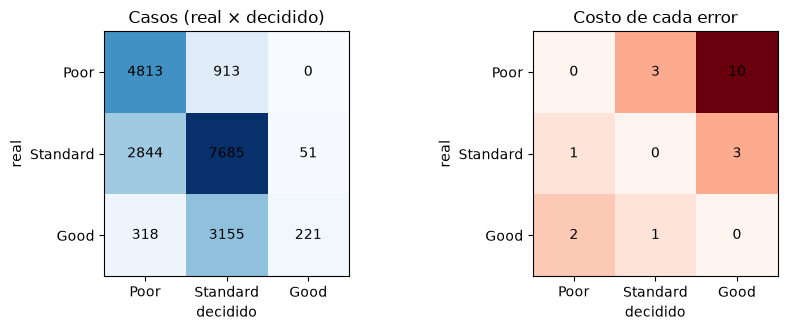

se marcan para revisión: 41.2% de los cliente-mes
de los clientes Poor reales: 92.5% quedan decididos como Poor o marcados para revisión
Poor reales que la decisión deja pasar como Good (el error más caro, costo 10): 0 de 5,726


In [10]:
decision = decide_min_cost(proba_test)
matriz = confusion_matrix(y_test, decision, labels=[0, 1, 2])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, datos, titulo, fmt in ((axes[0], matriz, "Casos (real × decidido)", "d"), (axes[1], COST_MATRIX, "Costo de cada error", ".0f")):
    ax.imshow(datos if titulo.startswith("Casos") else datos, cmap="Blues" if titulo.startswith("Casos") else "Reds")
    ax.set_xticks(range(3), CLASSES); ax.set_yticks(range(3), CLASSES); ax.set_xlabel("decidido"); ax.set_ylabel("real"); ax.set_title(titulo)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, format(datos[i, j], fmt), ha="center", va="center", color="black")
plt.tight_layout(); plt.show()

REVISION = 0.55   # misma regla que usa predict.py
revisar = (proba_test.max(axis=1) < REVISION) | (decision != proba_test.argmax(axis=1))
es_poor = y_test == 0
print(f"se marcan para revisión: {revisar.mean():.1%} de los cliente-mes")
print(f"de los clientes Poor reales: {(revisar | (decision == 0))[es_poor].mean():.1%} quedan decididos como Poor o marcados para revisión")
print(f"Poor reales que la decisión deja pasar como Good (el error más caro, costo 10): {((decision == 2) & es_poor).sum():,} de {es_poor.sum():,}")

In [11]:
# Errores por segmento: ¿el modelo funciona igual para todos?
seg = test[[GROUP_COL, "Age", "Annual_Income", "Occupation"]].copy()
seg["real"], seg["decidido"] = y_test, decision
seg["costo"] = COST_MATRIX[y_test, decision]
seg["edad"] = pd.cut(seg["Age"], [0, 25, 35, 50, 120], labels=["≤25", "26–35", "36–50", ">50"])
seg["ingreso"] = pd.qcut(seg["Annual_Income"], 3, labels=["bajo", "medio", "alto"])

def resumen(columna):
    g = seg.groupby(columna, observed=True)
    out = pd.DataFrame({
        "cliente-mes": g.size(), "costo medio": g["costo"].mean(),
        "% Poor real": g["real"].apply(lambda s: (s == 0).mean()),
        "recall Poor": g.apply(lambda d: (d.decidido[d.real == 0] == 0).mean()),
    })
    out.index = pd.MultiIndex.from_product([[columna], out.index.astype(str)])
    return out

segmentos = pd.concat([resumen("edad"), resumen("ingreso"), resumen("Occupation")])
segmentos.round(3)

cliente-mes  costo medio  % Poor real  recall Poor
edad       ≤25                   5568        0.436        0.328        0.908
           26–35                 5824        0.464        0.297        0.855
           36–50                 7192        0.501        0.283        0.803
           >50                   1416        0.559        0.097        0.333
ingreso    bajo                  6672        0.426        0.377        0.917
           medio                 6664        0.487        0.286        0.822
           alto                  6664        0.515        0.195        0.719
Occupation Accountant            1248        0.530        0.300        0.861
           Architect             1432        0.471        0.212        0.739
           Developer             1296        0.461        0.298        0.876
           Doctor                1464        0.550        0.308        0.747
           Engineer              1408        0.486        0.330        0.843
           Entrepreneur          1400        0.445        0.276        0.902
           Journalist            1304        0.472        0.236        0.886
           Lawyer                1344        0.499        0.274        0.856
           Manager               1408        0.502        0.256        0.806
           Mechanic              1504        0.432        0.300        0.858
           Media_Manager         1208        0.447        0.248        0.886
           Musician              1216        0.516        0.288        0.789
           Scientist             1312        0.455        0.330        0.834
           Teacher               1184        0.457        0.291        0.910
           Writer                1272        0.419        0.351        0.830

## 6. ¿Por qué decide así el modelo? — SHAP, con sus límites

SHAP reparte la predicción entre las variables: cuánto empuja cada una hacia `Poor`. Se calcula sobre una **muestra del
entrenamiento** (400 filas; la prueba no interviene) y sobre el modelo **sin calibrar**, porque la calibración solo reajusta
las probabilidades.

> **El límite que hay que escribir siempre:** SHAP explica **al modelo**, no **al mundo**. Que una variable pese mucho dice
> que el modelo se apoya en ella, no que *cause* el comportamiento de pago. Y como las variables están correlacionadas,
> el reparto entre ellas es una convención, no una verdad.

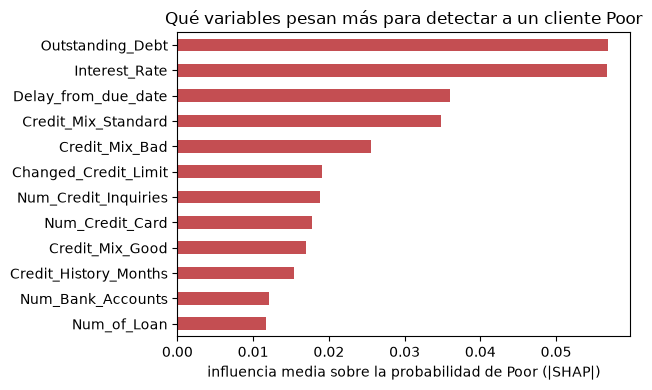

,hacia Poor,hacia Standard,hacia Good
Outstanding_Debt,0.057,0.044,0.018
Interest_Rate,0.057,0.041,0.020
Delay_from_due_date,0.036,0.018,0.022
Credit_Mix_Standard,0.035,0.078,0.046
Credit_Mix_Bad,0.026,0.013,0.014
Changed_Credit_Limit,0.019,0.021,0.006
Num_Credit_Inquiries,0.019,0.016,0.006
Num_Credit_Card,0.018,0.020,0.019
Credit_Mix_Good,0.017,0.050,0.060
Credit_History_Months,0.015,0.013,0.010


In [12]:
import shap

muestra = train.sample(400, random_state=0)
prep, arbol = base_final.named_steps["prep"], base_final.named_steps["model"]
Xt = prep.transform(muestra.drop(columns=[TARGET]))
nombres = [n.split("__", 1)[-1] for n in prep.get_feature_names_out()]
valores = shap.TreeExplainer(arbol).shap_values(Xt, check_additivity=False)
valores = np.stack(valores, axis=-1) if isinstance(valores, list) else valores        # (filas, variables, clases)

importancia = pd.DataFrame({f"hacia {c}": np.abs(valores[:, :, i]).mean(axis=0) for i, c in enumerate(CLASSES)}, index=nombres)
top = importancia.sort_values("hacia Poor", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(6.5, 4))
top["hacia Poor"][::-1].plot.barh(ax=ax, color="#c44e52")
ax.set_xlabel("influencia media sobre la probabilidad de Poor (|SHAP|)"); ax.set_title("Qué variables pesan más para detectar a un cliente Poor")
plt.tight_layout(); plt.show()
top.round(3)

In [13]:
# Variables de uso sensible o regulado entre las que usa el modelo
numericas, categoricas = base_final.named_steps["prep"].transformers_[0][2], base_final.named_steps["prep"].transformers_[1][2]
sensibles = [c for c in ("Age", "Occupation") if c in list(numericas) + list(categoricas)]
print("Variables de uso sensible o a revisar con el área legal antes de producción:", sensibles)
print("Peso de cada una (importancia media hacia Poor):")
print(importancia.loc[[n for n in importancia.index if any(n.startswith(s) for s in sensibles)], "hacia Poor"].round(3).to_string())

Variables de uso sensible o a revisar con el área legal antes de producción: ['Age', 'Occupation']
Peso de cada una (importancia media hacia Poor):
Age                         0.007
Occupation_Accountant       0.001
Occupation_Architect        0.001
Occupation_Developer        0.001
Occupation_Doctor           0.001
Occupation_Engineer         0.001
Occupation_Entrepreneur     0.001
Occupation_Journalist       0.001
Occupation_Lawyer           0.001
Occupation_Manager          0.000
Occupation_Mechanic         0.001
Occupation_Media_Manager    0.001
Occupation_Musician         0.001
Occupation_Scientist        0.001
Occupation_Teacher          0.001
Occupation_Writer           0.001


## 7. Guardar los resultados de la etapa

Salen de aquí: la tabla de resultados con intervalos (`reports/07_resultados.json`), los errores por segmento y la
importancia de variables. El reporte escrito `reports/07_validacion.md` se redacta **con estas cifras**, no de memoria.

In [14]:
resultados = {
    "modelo_final": nombre_final, "decisiones": decisiones["fecha_y_hora"],
    "prueba": {"filas": int(len(test)), "clientes": int(test[GROUP_COL].nunique())},
    "metricas_modelo": m_test, "metricas_baseline": m_base,
    "intervalos": intervalos.reset_index().to_dict(orient="records"),
    "supera_al_baseline_con_confianza": bool(supera),
    "revision": {"porcentaje_marcado": float(revisar.mean()), "poor_capturados": float((revisar | (decision == 0))[es_poor].mean())},
    "variables_sensibles": sensibles,
}
(REPORTS_DIR / "07_resultados.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
segmentos.round(4).to_csv(REPORTS_DIR / "07_errores_por_segmento.csv", encoding="utf-8")
importancia.sort_values("hacia Poor", ascending=False).round(4).to_csv(REPORTS_DIR / "07_importancia_shap.csv", encoding="utf-8")
print("guardado en", REPORTS_DIR)

guardado en C:\Users\Usuario\ab-casos-avanzados2026v2\ejemplo\reports
